# Section B - Visualization (Q155-179)

In [ ]:
import pandas as pd
import numpy as np
import re, datetime, warnings
from pathlib import Path
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
# Shared, unit-tested helpers (same folder; covered by test_preprocessing.py)
from preprocessing import (SYMBOL_TO_ISO, UNLABELLED, TARGET_CCY, RATES, RATES_SOURCE,
                           extract_currency, convert_to_target,
                           to_num, to_date, unify_flag, standardise_region)
pd.set_option("display.max_rows", 10)
pd.set_option("display.max_columns", 12)
pd.set_option("display.width", 200)
CANDS = [Path.cwd() / "Bank Records 1.xlsx"]
DATA = next((p for p in CANDS if p.exists()), None)
if DATA is None:
    for p in Path.cwd().rglob("Bank Records 1.xlsx"):
        DATA = p; break
print("DATA =", DATA)
OUTDIR = Path(DATA).parent
df = pd.read_excel(DATA)
raw = df.copy()
print("shape:", df.shape)
df.rename(columns={"customer_lifetime_value_amount (CLV)": "clv"}, inplace=True)

# ---------- B1/B5/B7: profile currency, capture ISO 4217, convert via rates ----------
MONEY = [c for c in ["account_balance", "Fixed_Deposite", "Credit_Amount"] if c in df.columns]
print("Currency label profile (B1):")
for c in MONEY:
    print(c, raw[c].apply(extract_currency).value_counts(dropna=False).to_dict())
for c in MONEY:
    df[c + "_ccy"] = raw[c].apply(extract_currency)
    df[c] = [convert_to_target(to_num(v), iso) for v, iso in zip(raw[c], df[c + "_ccy"])]
print(f"Rates: {RATES} (source: {RATES_SOURCE})")

# ---------- D2: unify flag encodings ----------
df["aml_flag"] = raw["aml_flag"].apply(unify_flag)
df["suspicious_txn_flag"] = raw["suspicious_txn_flag"].apply(unify_flag)

# ---------- region: standardised ONCE, reused by every chart below ----------
df["region_raw"] = df["region"]
df["region"] = raw["region"].apply(standardise_region)
print("region (standardised):", df["region"].value_counts(dropna=False).to_dict())

df["txn_date"] = raw["txn_date"].apply(to_date)
NUM = ["clv", "avg_transaction_value", "txn_frequency_30d", "txn_velocity_1hr", "failed_txn_count_24hr", "reward_points_earned"]
print("preprocessing done:", df.shape)


## Assumptions & Data-Quality Issues Log (I2/I4)

### Assumptions
1. **Currency** - every money cell carries an ISO 4217 label (EUR/INR/USD, including
   the mojibake `â‚¬`/`â‚¹` sequences) or is an *unlabelled* plain number. Unlabelled
   numbers are assumed to already be in the target currency (INR) and are flagged with
   `<col>_ccy = "UNLABELLED"` so the assumption stays visible.
2. **Rates** - conversions use a static documented table:
   `RATES = {INR: 1.0, USD: 83.5, EUR: 90.4}`, RBI reference rates as of 2025-01-01.
3. **Region** - one explicit `REGION_MAP` maps the 18 raw aliases (W1/W2/W3, SNorth,
   ENorth, Upper/Lower/Middle Region, `north east`, ...) to 8 canonical regions; applied
   once and reused by every chart.
4. **Dates** - `txn_date` and the loan offer-date columns are parsed format-by-format
   (not one blanket `errors="coerce"` call) and then cross-validated against the
   provided `year`/`month` columns.
5. **Loan join** - Loan_Records is many-rows-per-customer; it is aggregated to the
   latest offer per `customer_id` before a `validate="m:1"` join, so bank row count
   is preserved.
6. **Structural nulls** - `payment_gateway`/`txn_id_external` are only expected for
   certain txn_types; missing values there are structural, not true data loss.

## Assumptions & Data-Quality Issues Log (I2/I4)

### Assumptions
1. **Currency** - every money cell carries an ISO 4217 label (EUR/INR/USD, including
   the mojibake `â‚¬`/`â‚¹` sequences) or is an *unlabelled* plain number. Unlabelled
   numbers are assumed to already be in the target currency (INR) and are flagged with
   `<col>_ccy = "UNLABELLED"` so the assumption stays visible.
2. **Rates** - conversions use a static documented table:
   `RATES = {INR: 1.0, USD: 83.5, EUR: 90.4}`, RBI reference rates as of 2025-01-01.
3. **Region** - one explicit `REGION_MAP` maps the 18 raw aliases (W1/W2/W3, SNorth,
   ENorth, Upper/Lower/Middle Region, `north east`, ...) to 8 canonical regions; applied
   once and reused by every chart.
4. **Dates** - `txn_date` and the loan offer-date columns are parsed format-by-format
   (not one blanket `errors="coerce"` call) and then cross-validated against the
   provided `year`/`month` columns.
5. **Loan join** - Loan_Records is many-rows-per-customer; it is aggregated to the
   latest offer per `customer_id` before a `validate="m:1"` join, so bank row count
   is preserved.
6. **Structural nulls** - `payment_gateway`/`txn_id_external` are only expected for
   certain txn_types; missing values there are structural, not true data loss.

## Preprocessing tests

In [6]:
import pandas as pd
t = pd.DataFrame({"a": ["INR 200", "$10k", "500"], "d": ["February4-February-2025", "28122026", "15/07/2022"]})
t["a"] = t["a"].apply(to_num); t["d"] = t["d"].apply(to_date)
print(t.to_string())
assert list(t["a"]) == [200.0, 10000.0, 500.0]
assert str(t.loc[0, "d"].date()) == "2025-02-04"
print("Preprocessing tests passed")


         a          d
0    200.0 2025-02-04
1  10000.0 2026-12-28
2    500.0 2022-07-15
Preprocessing tests passed


## Q155 - Create a histogram with 30 bins showing the distribution of CLV

In [ ]:
clv = df["clv"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(clv.dropna(), bins=30, edgecolor="black")
axes[0].axvline(clv.mean(), color="red", linestyle="--", label="Mean CLV")
axes[0].set_title("Distribution of Customer Lifetime Value")
axes[0].set_xlabel("Customer Lifetime Value")
axes[0].set_ylabel("Number of Customers")
axes[0].legend()
# H5: CLV is strongly right-skewed - show a log1p view so the tail is readable
axes[1].hist(np.log1p(clv.dropna()), bins=30, edgecolor="black", color="darkorange")
axes[1].set_title("log1p(CLV) - skew handled")
axes[1].set_xlabel("log1p(Customer Lifetime Value)")
axes[1].set_ylabel("Number of Customers")
print("CLV skew:", round(float(clv.skew()), 2), "| p99:", round(float(clv.quantile(0.99)), 2))
plt.tight_layout()
plt.savefig("clv_distribution.png")
plt.show()


## Q156 - Create a 2x2 subplot grid

NameError: name 'sns' is not defined

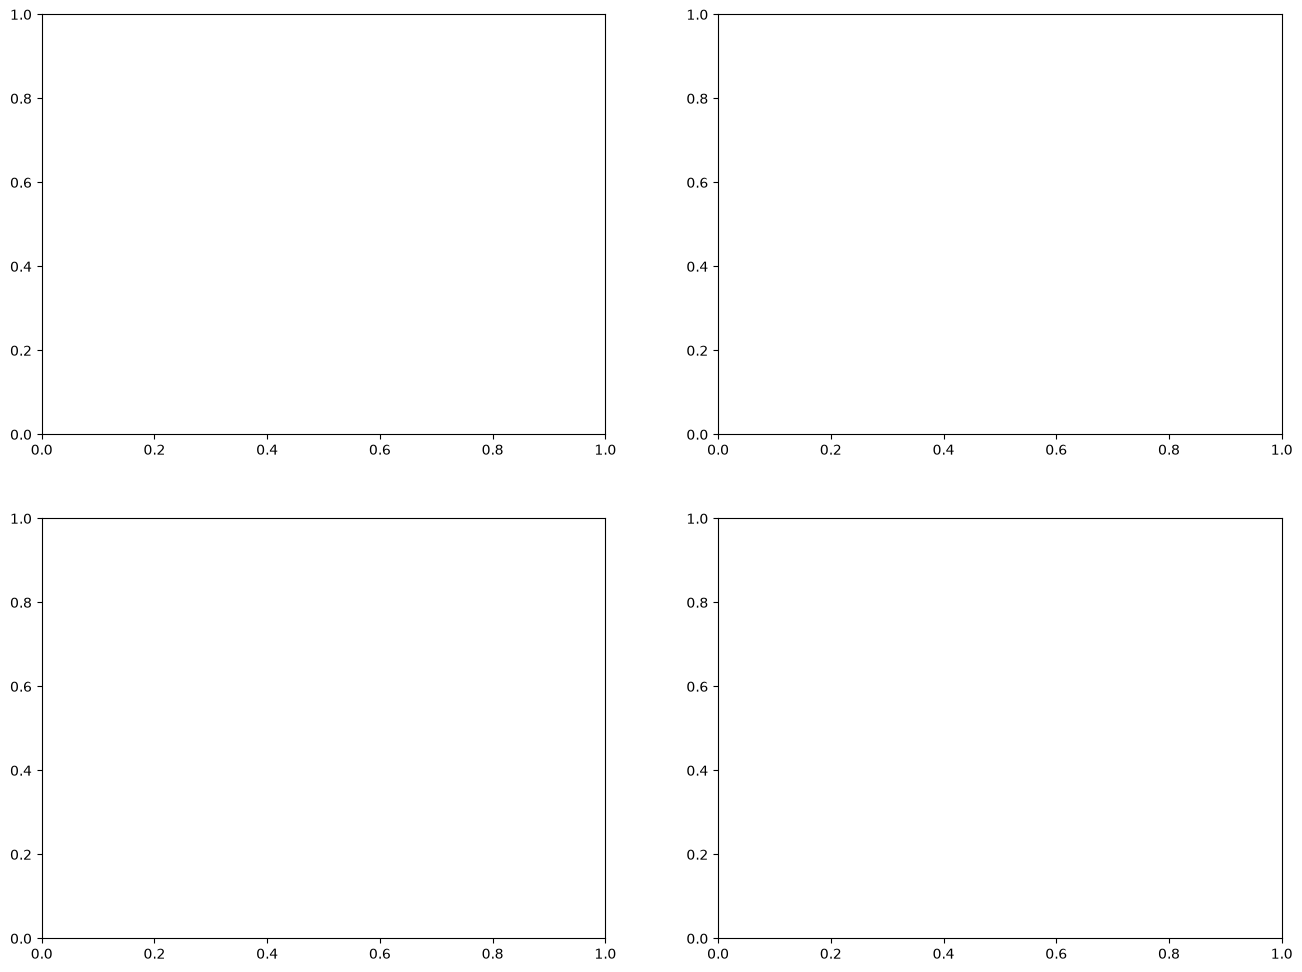

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
sns.boxplot(
    data=df,
    x="region",
    y="clv",
    ax=axes[0, 0]
)
axes[0, 0].set_title("CLV by Region")
axes[0, 0].set_xlabel("Region")
axes[0, 0].set_ylabel("CLV")
sns.violinplot(
    data=df,
    x="customer_activity_status",
    y="txn_frequency_30d",
    ax=axes[0, 1]
)
axes[0, 1].set_title("Transaction Frequency by Activity Status")
axes[0, 1].set_xlabel("Customer Activity Status")
axes[0, 1].set_ylabel("Transaction Frequency")
segment_clv = df.groupby(
    "customer_segment"
)["clv"].mean().reset_index()
sns.barplot(
    data=segment_clv,
    x="customer_segment",
    y="clv",
    ax=axes[1, 0]
)
axes[1, 0].set_title("Average CLV by Customer Segment")
axes[1, 0].set_xlabel("Customer Segment")
axes[1, 0].set_ylabel("Average CLV")
time_count = df["most_common_txn_time_of_day"].value_counts()
sns.barplot(
    x=time_count.index,
    y=time_count.values,
    ax=axes[1, 1]
)
axes[1, 1].set_title("Transaction Time of Day")
axes[1, 1].set_xlabel("Time of Day")
axes[1, 1].set_ylabel("Transaction Count")
plt.tight_layout()
plt.show()

## Q157 - Correlation heatmap of numeric columns with annotations

In [ ]:
numeric_data = df.select_dtypes(include="number")
correlation = numeric_data.corr()
plt.figure(figsize=(16, 12))
sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)
plt.title("Correlation Heatmap of Numeric Columns")
plt.tight_layout()
plt.show()

## Q158 - Create a scatter plot with CLV on the x-axis and avg_transaction_value on the y-axis. Color points by customer_activity_status and add a regression line for each status group.

In [9]:
plt.figure(figsize=(12, 7))
sns.scatterplot(
    data=df,
    x="clv",
    y="avg_transaction_value",
    hue="customer_activity_status",
    alpha=0.6
)
for status in df["customer_activity_status"].dropna().unique():
    status_data = df[
        df["customer_activity_status"] == status
    ]
    sns.regplot(
        data=status_data,
        x="clv",
        y="avg_transaction_value",
        scatter=False,
        label=f"{status} trend"
    )
plt.title("CLV vs Average Transaction Value")
plt.xlabel("Customer Lifetime Value")
plt.ylabel("Average Transaction Value")
plt.legend()
plt.show()

NameError: name 'sns' is not defined

<Figure size 1200x700 with 0 Axes>

## Q159 - Plot a time series line chart showing monthly transaction count over the entire date range. Overlay a 3-month rolling average as a dashed line in a different color with a legend

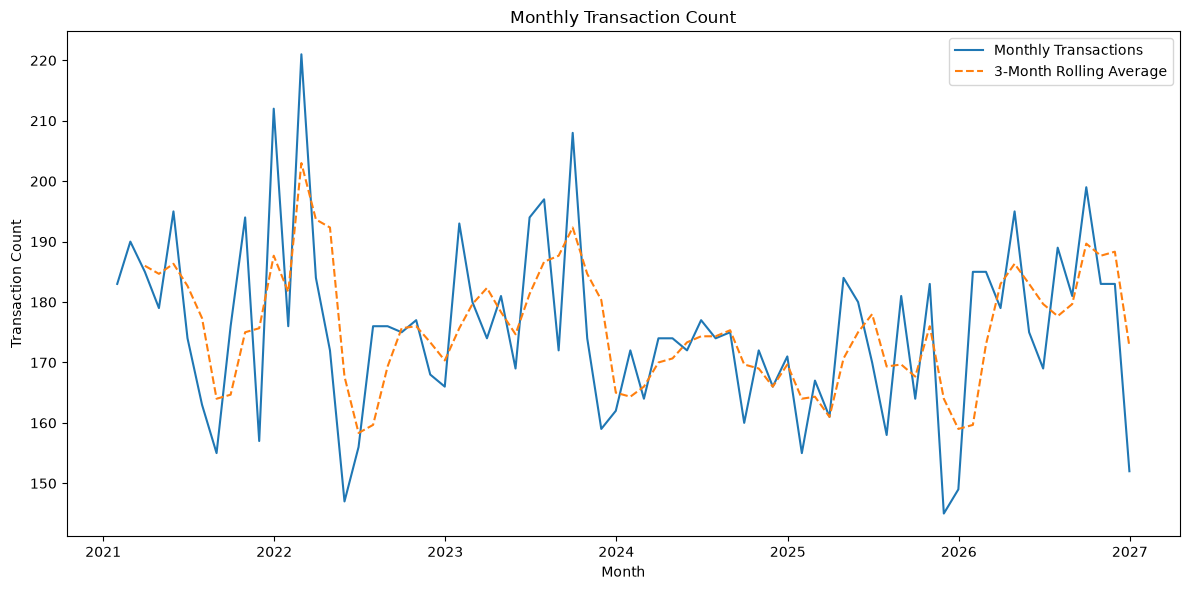

In [10]:
df["txn_date"] = pd.to_datetime(
    df["txn_date"],
    errors="coerce"
)
monthly_transactions = df.set_index(
    "txn_date"
).resample("ME").size()
rolling_average = monthly_transactions.rolling(
    3
).mean()
plt.figure(figsize=(12, 6))
plt.plot(
    monthly_transactions.index,
    monthly_transactions.values,
    label="Monthly Transactions"
)
plt.plot(
    rolling_average.index,
    rolling_average.values,
    linestyle="--",
    label="3-Month Rolling Average"
)
plt.title("Monthly Transaction Count")
plt.xlabel("Month")
plt.ylabel("Transaction Count")
plt.legend()
plt.tight_layout()
plt.show()

## Q160 - Create a stacked bar chart showing payment method distribution for each customer segment. Display percentage values as annotations on each bar section

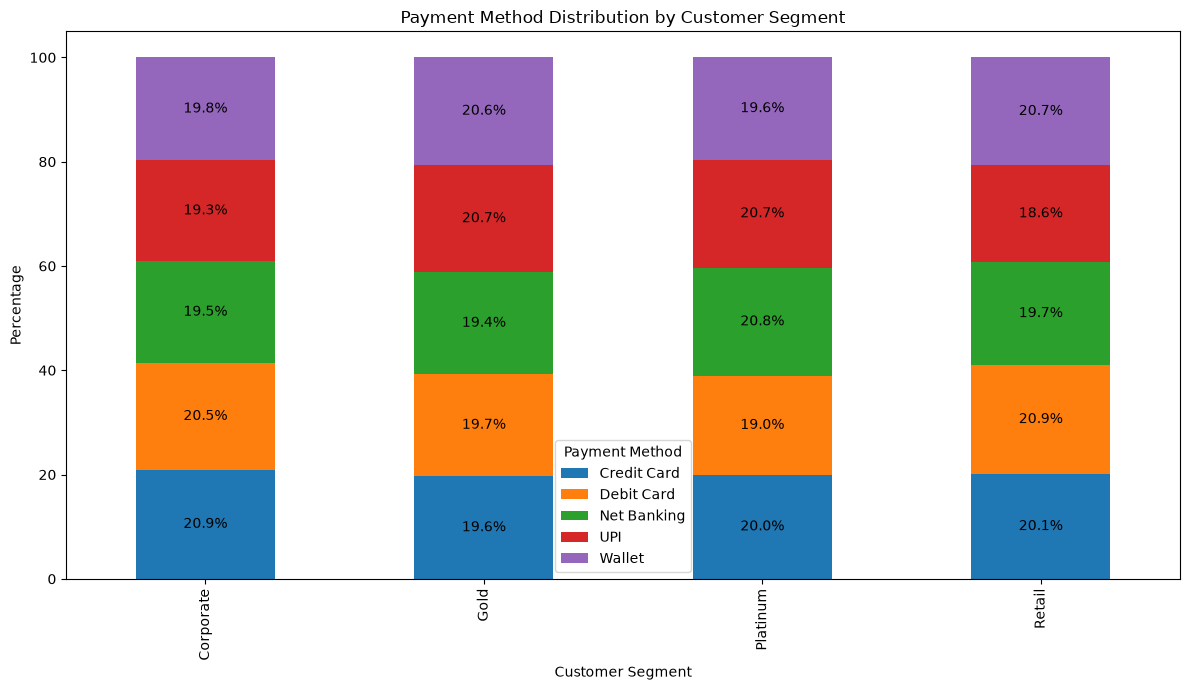

In [11]:
payment_data = pd.crosstab(
    df["customer_segment"],
    df["payment_method"],
    normalize="index"
) * 100
ax = payment_data.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 7)
)
plt.title("Payment Method Distribution by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Percentage")
plt.legend(title="Payment Method")
for container in ax.containers:
    labels = [
        f"{value.get_height():.1f}%"
        if value.get_height() > 3 else ""
        for value in container
    ]
    ax.bar_label(
        container,
        labels=labels,
        label_type="center"
    )
plt.tight_layout()
plt.show()

## Q161 - Generate a pairplot for six key numeric columns

In [12]:
pair_data = df[
    [
        "clv",
        "avg_transaction_value",
        "txn_frequency_30d",
        "txn_velocity_1hr",
        "reward_points_earned",
        "failed_txn_count_24hr",
        "region"
    ]
].dropna()
sns.pairplot(
    pair_data,
    hue="region"
)
plt.show()

NameError: name 'sns' is not defined

## Q162 - Pie chart showing customer activity status distribution

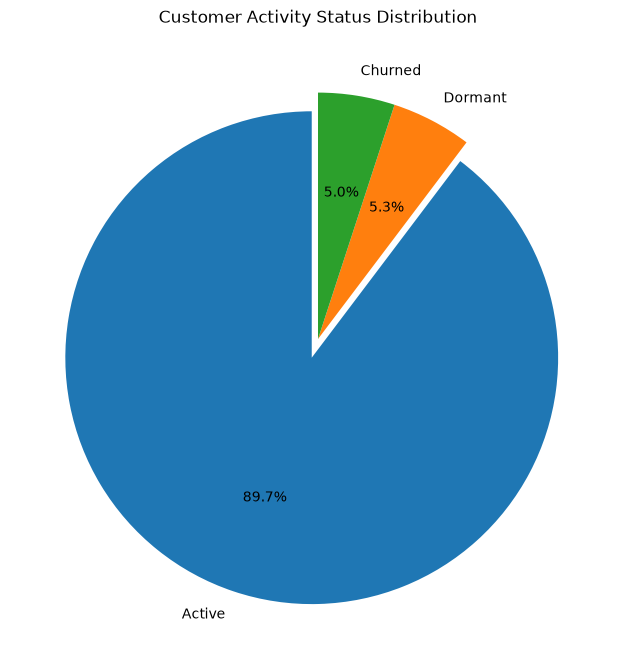

In [13]:
activity_count = df[
    "customer_activity_status"
].value_counts()
plt.figure(figsize=(8, 8))
explode = [
    0.08 if status == "Active" else 0
    for status in activity_count.index
]
plt.pie(
    activity_count.values,
    labels=activity_count.index,
    autopct="%1.1f%%",
    explode=explode,
    startangle=90
)
plt.title("Customer Activity Status Distribution")
plt.show()

## Q163 - Horizontal bar chart of top 10 customers by CLV

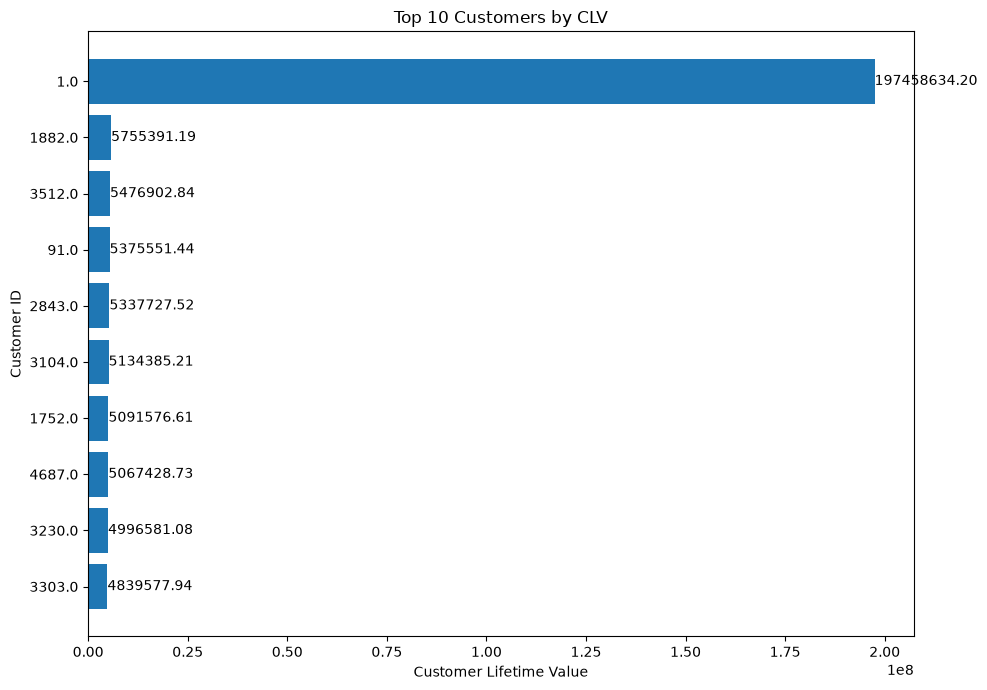

In [14]:
customer_clv = df.groupby(
    "customer_id"
)["clv"].max().sort_values(
    ascending=False
).head(10)
plt.figure(figsize=(10, 7))
bars = plt.barh(
    customer_clv.index.astype(str),
    customer_clv.values
)
plt.gca().invert_yaxis()
plt.title("Top 10 Customers by CLV")
plt.xlabel("Customer Lifetime Value")
plt.ylabel("Customer ID")
for bar in bars:
    plt.text(
        bar.get_width(),
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.2f}",
        va="center"
    )
plt.tight_layout()
plt.savefig("top10_clv_customers.png")
plt.show()

## Q164 - Box plot of transaction velocity by fraud risk level with individual points

In [15]:
plt.figure(figsize=(10, 7))
sns.boxplot(
    data=df,
    x="fraud_risk_level",
    y="txn_velocity_1hr"
)
sns.swarmplot(
    data=df.sample(
        min(1000, len(df)),
        random_state=42
    ),
    x="fraud_risk_level",
    y="txn_velocity_1hr",
    alpha=0.4,
    size=3
)
plt.title("Transaction Velocity by Fraud Risk Level")
plt.xlabel("Fraud Risk Level")
plt.ylabel("Transaction Velocity (1 Hour)")
plt.tight_layout()
plt.show()

NameError: name 'sns' is not defined

<Figure size 1000x700 with 0 Axes>

## Q165 - Faceted bar charts showing monthly transaction counts for each region

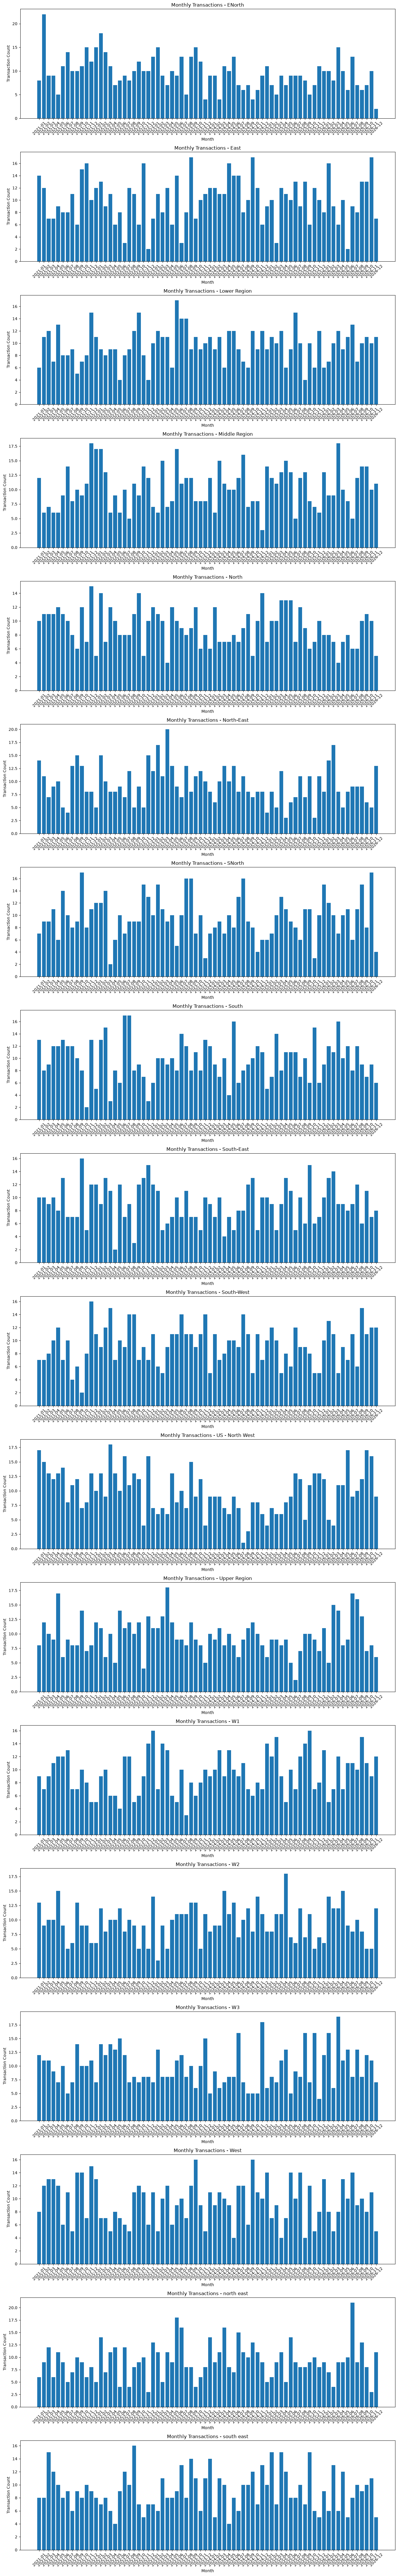

In [16]:
df["txn_date"] = pd.to_datetime(
    df["txn_date"],
    errors="coerce"
)
monthly_region = (
    df.dropna(subset=["txn_date"])
    .assign(month=lambda x: x["txn_date"].dt.to_period("M").astype(str))
    .groupby(["region", "month"])
    .size()
    .reset_index(name="transaction_count")
)
regions = monthly_region["region"].dropna().unique()
fig, axes = plt.subplots(
    len(regions),
    1,
    figsize=(14, 5 * len(regions)),
    squeeze=False
)
for i, region in enumerate(regions):
    region_data = monthly_region[
        monthly_region["region"] == region
    ]
    axes[i, 0].bar(
        region_data["month"],
        region_data["transaction_count"]
    )
    axes[i, 0].set_title(
        f"Monthly Transactions - {region}"
    )
    axes[i, 0].set_xlabel("Month")
    axes[i, 0].set_ylabel("Transaction Count")
    axes[i, 0].tick_params(
        axis="x",
        rotation=45
    )
plt.tight_layout()
plt.show()

## Q166 - KDE plot comparing CLV for customers who applied offers vs did not

In [17]:
offer_applied = df[df["offer_applied_flag"] == 1][
    "clv"
].dropna()
offer_not_applied = df[df["offer_applied_flag"] == 0][
    "clv"
].dropna()
plt.figure(figsize=(10, 6))
sns.kdeplot(
    offer_applied,
    fill=True,
    alpha=0.4,
    label="Offer Applied"
)
sns.kdeplot(
    offer_not_applied,
    fill=True,
    alpha=0.4,
    label="Offer Not Applied"
)
plt.axvline(
    offer_applied.median(),
    linestyle="--",
    label="Median - Offer Applied"
)
plt.axvline(
    offer_not_applied.median(),
    linestyle="--",
    label="Median - Offer Not Applied"
)
plt.title("CLV Distribution: Offer Applied vs Not Applied")
plt.xlabel("Customer Lifetime Value")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()

NameError: name 'sns' is not defined

<Figure size 1000x600 with 0 Axes>

## Q167 - Bubble chart with CLV, average transaction value,

In [ ]:
# transaction frequency and region
bubble_data = df.copy()
bubble_data["clv"] = pd.to_numeric(
    bubble_data["clv"],
    errors="coerce"
)
bubble_data["avg_transaction_value"] = pd.to_numeric(
    bubble_data["avg_transaction_value"],
    errors="coerce"
)
bubble_data["txn_frequency_30d"] = pd.to_numeric(
    bubble_data["txn_frequency_30d"],
    errors="coerce"
)
bubble_data = bubble_data.dropna(
    subset=[
        "clv",
        "avg_transaction_value",
        "txn_frequency_30d",
        "region"
    ]
)
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=bubble_data,
    x="clv",
    y="avg_transaction_value",
    size="txn_frequency_30d",
    hue="region",
    sizes=(20, 500),
    alpha=0.6
)
plt.title("CLV vs Average Transaction Value")
plt.xlabel("Customer Lifetime Value")
plt.ylabel("Average Transaction Value")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

NameError: name 'sns' is not defined

<Figure size 1000x600 with 0 Axes>

: 

## Q168 - Pivot table heatmap of transaction count

In [18]:
pivot_table = pd.pivot_table(
    df,
    index="region",
    columns="payment_method",
    values="transaction_id",
    aggfunc="count",
    fill_value=0
)
plt.figure(figsize=(10, 6))
sns.heatmap(
    pivot_table,
    annot=True,
    fmt="d",
    cmap="YlGnBu"
)
plt.title("Transaction Count by Region and Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Region")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

NameError: name 'sns' is not defined

<Figure size 1000x600 with 0 Axes>

## Q169 - Cumulative distribution function of CLV

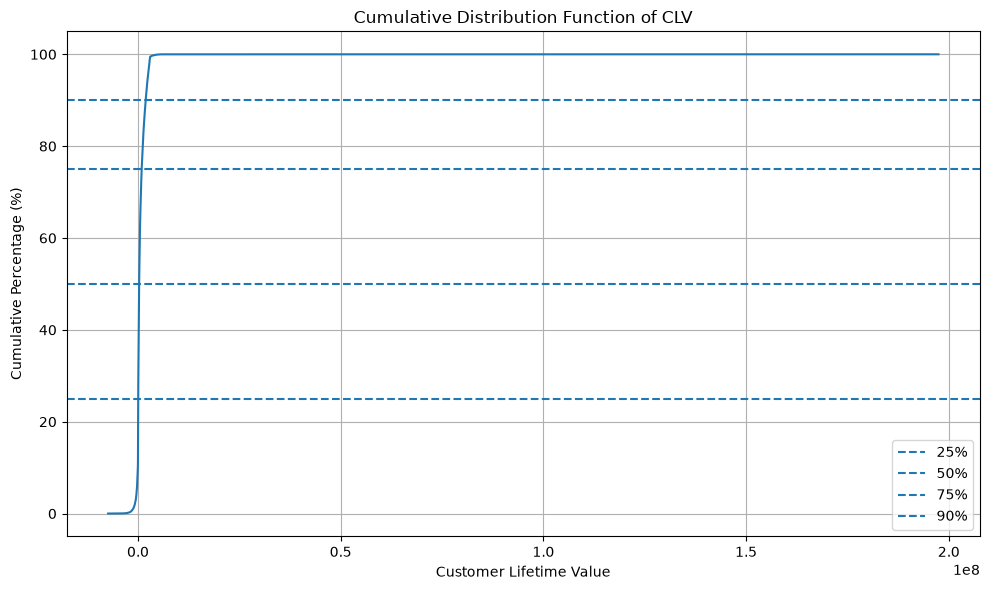

In [19]:
clv_values = pd.to_numeric(
    df["clv"],
    errors="coerce"
).dropna()
clv_values = np.sort(clv_values)
cumulative_percentage = (
    np.arange(1, len(clv_values) + 1) / len(clv_values)
) * 100
plt.figure(figsize=(10, 6))
plt.plot(
    clv_values,
    cumulative_percentage
)
plt.axhline(25, linestyle="--", label="25%")
plt.axhline(50, linestyle="--", label="50%")
plt.axhline(75, linestyle="--", label="75%")
plt.axhline(90, linestyle="--", label="90%")
plt.title("Cumulative Distribution Function of CLV")
plt.xlabel("Customer Lifetime Value")
plt.ylabel("Cumulative Percentage (%)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## Q170 - Monthly CLV trends for top 4 regions by total CLV

In [ ]:
clv_for_region = pd.to_numeric(
    df["clv"],
    errors="coerce"
)
region_clv = (
    df.assign(clv_clean=clv_for_region)
    .groupby("region")["clv_clean"]
    .sum()
    .sort_values(ascending=False)
)
top_4_regions = region_clv.head(4).index
df["txn_date"] = pd.to_datetime(
    df["txn_date"],
    errors="coerce"
)
monthly_clv = (
    df[df["region"].isin(top_4_regions)]
    .assign(
        clv_clean=pd.to_numeric(
            df["clv"],
            errors="coerce"
        )
    )
    .groupby([
        "region",
        pd.Grouper(key="txn_date", freq="ME")
    ])["clv_clean"]
    .sum()
    .reset_index()
)
plt.figure(figsize=(12, 6))
for region in top_4_regions:
    region_data = monthly_clv[
        monthly_clv["region"] == region
    ]
    plt.plot(
        region_data["txn_date"],
        region_data["clv_clean"],
        marker="o",
        label=region
    )
plt.title("Monthly CLV Trends - Top 4 Regions")
plt.xlabel("Month")
plt.ylabel("Total CLV")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

NameError: name 'pd' is not defined

## Q171 - Donut chart for weekend vs weekday high-value transactions

In [ ]:
weekend_flag = pd.to_numeric(
    df["averag_high_txn_weekend_flag"],
    errors="coerce"
)
weekend = (weekend_flag == 1).sum()
weekday = (weekend_flag == 0).sum()
values = [weekend, weekday]
labels = ["Weekend", "Weekday"]
weekend_percentage = (
    weekend / sum(values)
) * 100
plt.figure(figsize=(7, 7))
plt.pie(
    values,
    labels=labels,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.4}
)
plt.text(
    0,
    0,
    f"{weekend_percentage:.1f}%\nWeekend",
    ha="center",
    va="center",
    fontsize=12
)
plt.title("Weekend vs Weekday High-Value Transactions")
plt.show()

NameError: name 'pd' is not defined

## Q172 - 1x3 subplot for cleaned account balance

NameError: name 'sns' is not defined

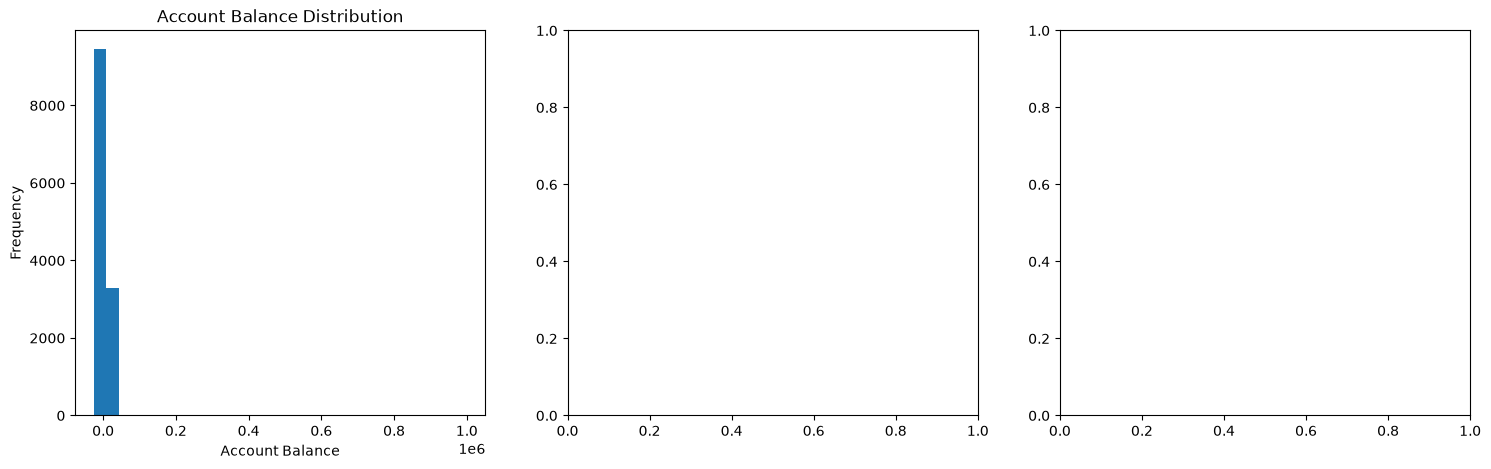

In [30]:
df["account_balance_clean"] = pd.to_numeric(
    df["account_balance"],
    errors="coerce"
)
clean_balance = df["account_balance_clean"].dropna()
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
# (a) Histogram
axes[0].hist(
    clean_balance,
    bins=30
)
axes[0].set_title("Account Balance Distribution")
axes[0].set_xlabel("Account Balance")
axes[0].set_ylabel("Frequency")
# (b) Box plot
sns.boxplot(
    data=df,
    x="customer_segment",
    y="account_balance_clean",
    ax=axes[1]
)
axes[1].set_title("Account Balance by Customer Segment")
axes[1].set_xlabel("Customer Segment")
axes[1].set_ylabel("Account Balance")
# (c) KDE Active vs Churned
active_balance = df[
    df["customer_activity_status"] == "Active"
]["account_balance_clean"].dropna()
churned_balance = df[
    df["customer_activity_status"] == "Churned"
]["account_balance_clean"].dropna()
sns.kdeplot(
    active_balance,
    fill=True,
    alpha=0.4,
    label="Active",
    ax=axes[2]
)
sns.kdeplot(
    churned_balance,
    fill=True,
    alpha=0.4,
    label="Churned",
    ax=axes[2]
)
axes[2].set_title("Account Balance: Active vs Churned")
axes[2].set_xlabel("Account Balance")
axes[2].set_ylabel("Density")
axes[2].legend()
plt.tight_layout()
plt.show()

## Q173 - Lag-1 scatter plot

In [21]:
df["Credit_Amount_clean"] = pd.to_numeric(
    df["Credit_Amount"],
    errors="coerce"
)
lag_data = df.sort_values(
    ["customer_id", "txn_date"]
).copy()
lag_data["next_transaction_amount"] = (
    lag_data.groupby("customer_id")[
        "Credit_Amount_clean"
    ].shift(-1)
)
lag_data = lag_data.dropna(
    subset=[
        "Credit_Amount_clean",
        "next_transaction_amount"
    ]
)
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=lag_data,
    x="Credit_Amount_clean",
    y="next_transaction_amount",
    alpha=0.5
)
max_value = max(
    lag_data["Credit_Amount_clean"].max(),
    lag_data["next_transaction_amount"].max()
)
plt.plot(
    [0, max_value],
    [0, max_value],
    linestyle="--",
    label="y = x"
)
plt.title("Lag-1 Transaction Amount Scatter Plot")
plt.xlabel("Current Transaction Amount")
plt.ylabel("Next Transaction Amount")
plt.legend()
plt.tight_layout()
plt.show()

NameError: name 'sns' is not defined

<Figure size 1000x600 with 0 Axes>

## Q174 - Cumulative CLV contribution

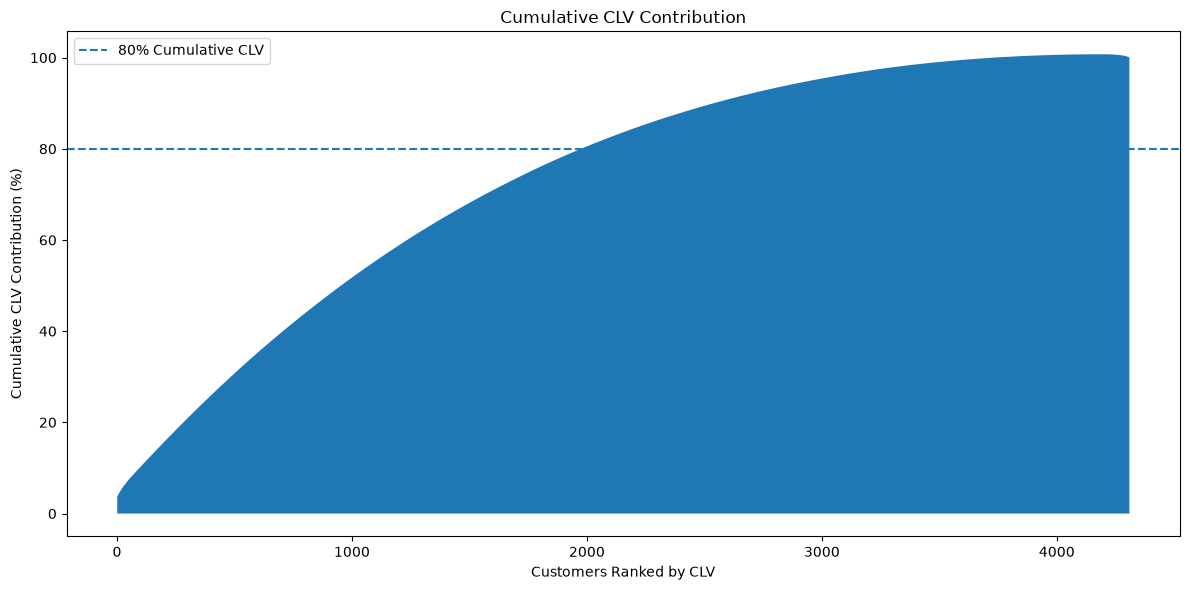

In [22]:
customer_clv = (
    df.groupby("customer_id")[
        "clv"
    ]
    .max()
    .sort_values(ascending=False)
)
customer_clv = pd.to_numeric(
    customer_clv,
    errors="coerce"
).dropna()
cumulative_clv = customer_clv.cumsum()
cumulative_percentage = (
    cumulative_clv / customer_clv.sum()
) * 100
plt.figure(figsize=(12, 6))
plt.fill_between(
    range(1, len(cumulative_percentage) + 1),
    cumulative_percentage
)
plt.axhline(
    80,
    linestyle="--",
    label="80% Cumulative CLV"
)
plt.title("Cumulative CLV Contribution")
plt.xlabel("Customers Ranked by CLV")
plt.ylabel("Cumulative CLV Contribution (%)")
plt.legend()
plt.tight_layout()
plt.show()

## Q175 - Cluster map of correlation matrix

In [29]:
numeric_data = df.select_dtypes(
    include="number"
)
correlation_matrix = numeric_data.corr()
sns.clustermap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    figsize=(14, 12)
)
plt.show()

NameError: name 'sns' is not defined

## Q176 - Count plot of transaction time of day

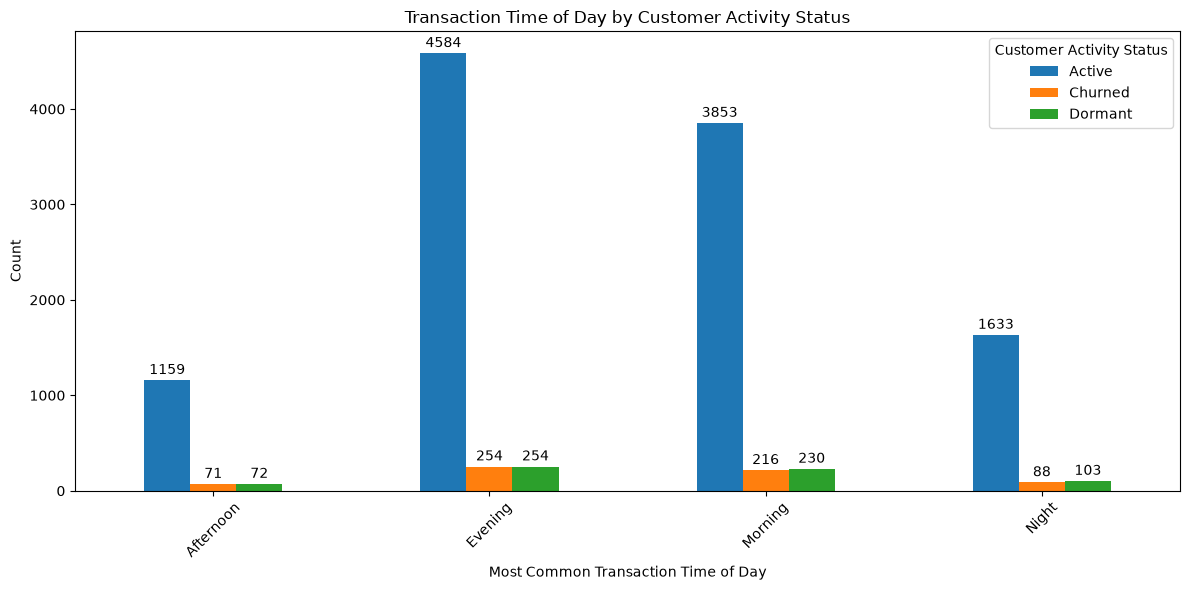

In [24]:
# split by customer activity status
time_status = pd.crosstab(
    df["most_common_txn_time_of_day"],
    df["customer_activity_status"]
)
ax = time_status.plot(
    kind="bar",
    figsize=(12, 6)
)
plt.title(
    "Transaction Time of Day by Customer Activity Status"
)
plt.xlabel("Most Common Transaction Time of Day")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.legend(title="Customer Activity Status")
# Percentage annotations
for container in ax.containers:
    labels = []
    for bar in container:
        height = bar.get_height()
        if height > 0:
            labels.append(f"{height:.0f}")
        else:
            labels.append("")
    ax.bar_label(
        container,
        labels=labels,
        padding=2
    )
plt.tight_layout()
plt.show()

## Q177 - Payment gateways by average transaction amount

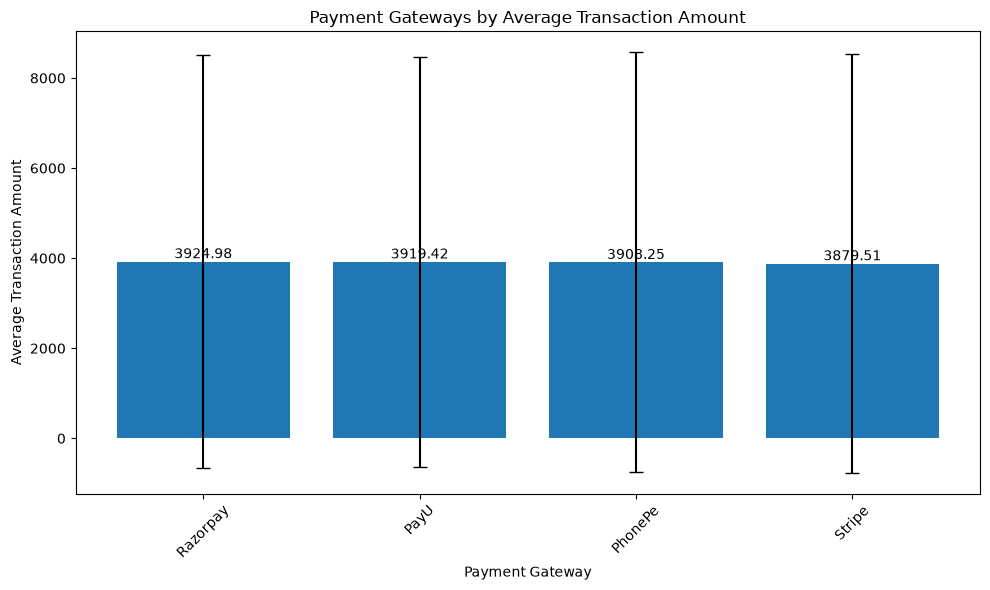

In [25]:
# Convert Credit_Amount to numeric first
df["Credit_Amount_clean"] = pd.to_numeric(
    df["Credit_Amount"],
    errors="coerce"
)
gateway_data = df.dropna(
    subset=[
        "payment_gateway",
        "Credit_Amount_clean"
    ]
)
gateway_stats = (
    gateway_data
    .groupby("payment_gateway")["Credit_Amount_clean"]
    .agg(["mean", "std"])
    .sort_values("mean", ascending=False)
)
plt.figure(figsize=(10, 6))
bars = plt.bar(
    gateway_stats.index,
    gateway_stats["mean"],
    yerr=gateway_stats["std"],
    capsize=5
)
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{bar.get_height():.2f}",
        ha="center",
        va="bottom"
    )
plt.title(
    "Payment Gateways by Average Transaction Amount"
)
plt.xlabel("Payment Gateway")
plt.ylabel("Average Transaction Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Q178 - Investment dashboard

NameError: name 'sns' is not defined

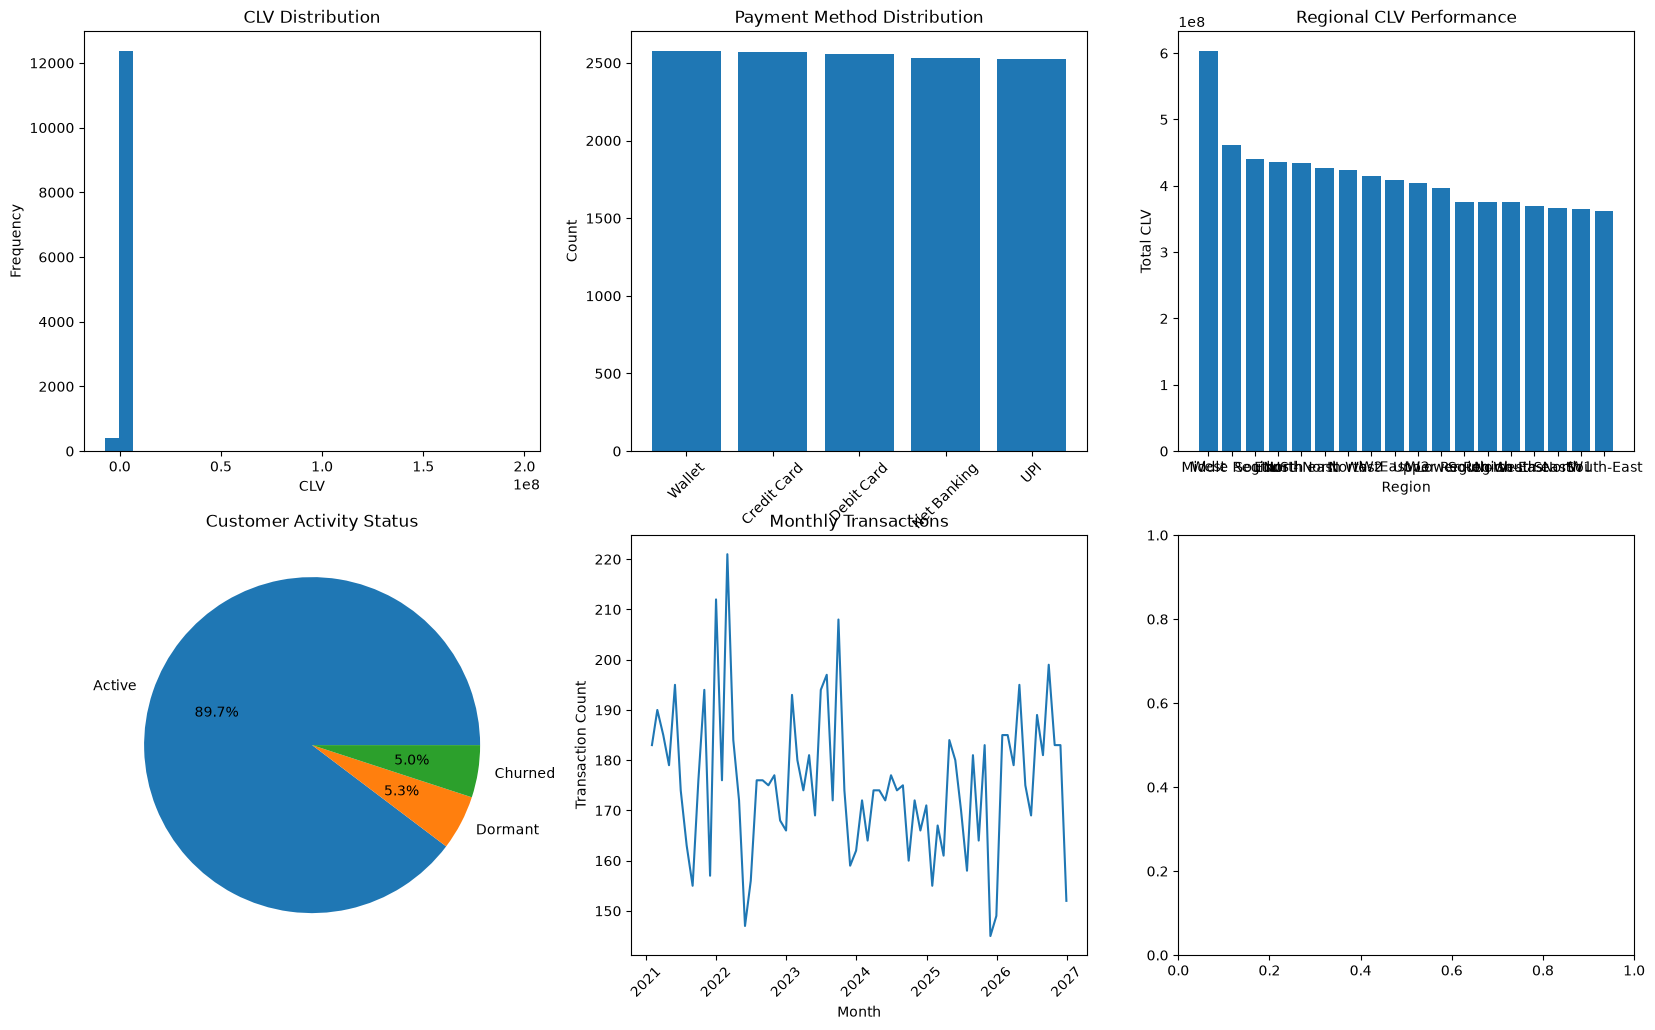

In [28]:
fig, axes = plt.subplots(
    2,
    3,
    figsize=(20, 12)
)
# (a) CLV histogram
clv_data = pd.to_numeric(
    df["clv"],
    errors="coerce"
).dropna()
axes[0, 0].hist(
    clv_data,
    bins=30
)
axes[0, 0].set_title("CLV Distribution")
axes[0, 0].set_xlabel("CLV")
axes[0, 0].set_ylabel("Frequency")
# (b) Payment method bar chart
payment_counts = df["payment_method"].value_counts()
axes[0, 1].bar(
    payment_counts.index,
    payment_counts.values
)
axes[0, 1].set_title("Payment Method Distribution")
axes[0, 1].set_xlabel("Payment Method")
axes[0, 1].set_ylabel("Count")
axes[0, 1].tick_params(
    axis="x",
    rotation=45
)
# (c) Regional performance
regional_clv = (
    df.assign(
        clv_clean=pd.to_numeric(
            df["clv"],
            errors="coerce"
        )
    )
    .groupby("region")["clv_clean"]
    .sum()
    .sort_values(ascending=False)
)
axes[0, 2].bar(
    regional_clv.index,
    regional_clv.values
)
axes[0, 2].set_title("Regional CLV Performance")
axes[0, 2].set_xlabel("Region")
axes[0, 2].set_ylabel("Total CLV")
# (d) Activity status pie chart
activity_counts = df[
    "customer_activity_status"
].value_counts()
axes[1, 0].pie(
    activity_counts,
    labels=activity_counts.index,
    autopct="%1.1f%%"
)
axes[1, 0].set_title(
    "Customer Activity Status"
)
# (e) Monthly transaction time series
monthly_transactions = (
    df.set_index("txn_date")
    .resample("ME")
    .size()
)
axes[1, 1].plot(
    monthly_transactions.index,
    monthly_transactions.values
)
axes[1, 1].set_title("Monthly Transactions")
axes[1, 1].set_xlabel("Month")
axes[1, 1].set_ylabel("Transaction Count")
axes[1, 1].tick_params(
    axis="x",
    rotation=45
)
# (f) Correlation heatmap
corr = df.select_dtypes(
    include="number"
).corr()
sns.heatmap(
    corr,
    cmap="coolwarm",
    ax=axes[1, 2],
    cbar=False
)
axes[1, 2].set_title(
    "Correlation Heatmap"
)
fig.suptitle(
    "Investment Dashboard",
    fontsize=20
)
plt.tight_layout()
plt.savefig(
    "investment_dashboard.png"
)
plt.show()

## Q179 - Create four CLV tiers

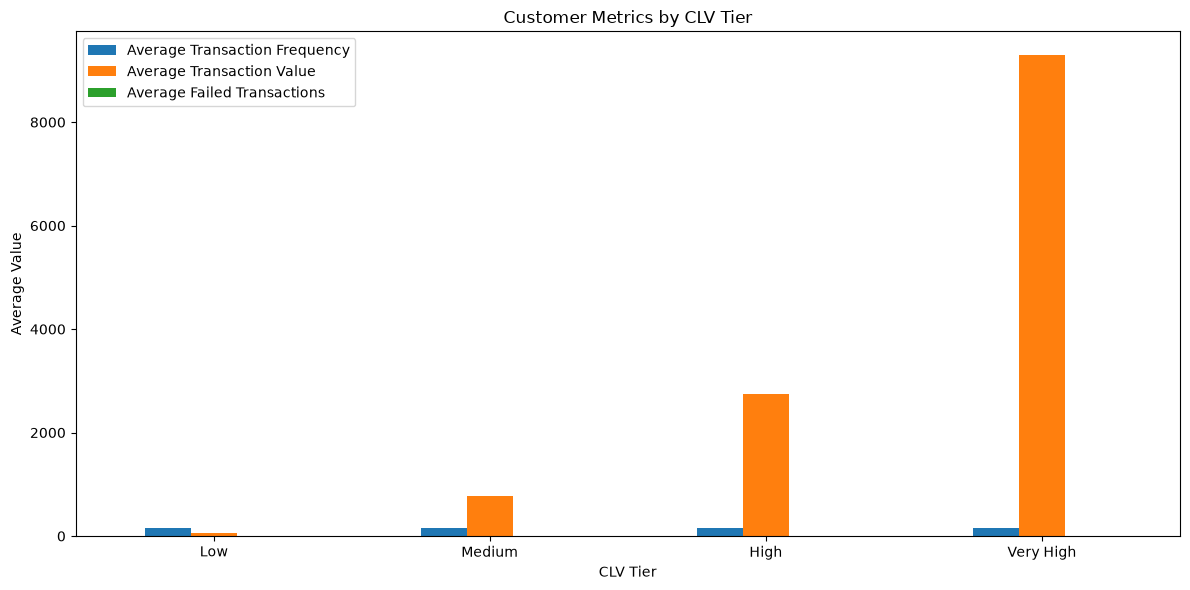

In [27]:
df["CLV_Tier"] = pd.qcut(
    clv_data,
    q=4,
    labels=[
        "Low",
        "Medium",
        "High",
        "Very High"
    ]
)
# Use the original index so the tier matches each row
df["CLV_Tier"] = pd.qcut(
    df["clv"],
    q=4,
    labels=[
        "Low",
        "Medium",
        "High",
        "Very High"
    ],
    duplicates="drop"
)
# Convert required columns to numeric
df["txn_frequency_30d_clean"] = pd.to_numeric(
    df["txn_frequency_30d"],
    errors="coerce"
)
df["avg_transaction_value_clean"] = pd.to_numeric(
    df["avg_transaction_value"],
    errors="coerce"
)
df["failed_txn_count_24hr_clean"] = pd.to_numeric(
    df["failed_txn_count_24hr"],
    errors="coerce"
)
tier_summary = df.groupby(
    "CLV_Tier",
    observed=False
)[
    [
        "txn_frequency_30d_clean",
        "avg_transaction_value_clean",
        "failed_txn_count_24hr_clean"
    ]
].mean()
ax = tier_summary.plot(
    kind="bar",
    figsize=(12, 6)
)
plt.title(
    "Customer Metrics by CLV Tier"
)
plt.xlabel("CLV Tier")
plt.ylabel("Average Value")
plt.xticks(rotation=0)
plt.legend([
    "Average Transaction Frequency",
    "Average Transaction Value",
    "Average Failed Transactions"
])
plt.tight_layout()
plt.show()